# Results: four anomalies, long-short backtest

Four signals, three universes (largest 500, 1000 and 3000 US common stocks by market cap), holding months 2006-01 to 2026-10
(250 months; the signals use data from before 2006 to fill in their look-back windows).

Each month-end we sort the universe into 10 groups by score, hold every group for the next month with
equal weights, and look at **long-short = top group minus bottom group**.

All returns are **before transaction costs**.

| Signal | Score at month-end t (higher = buy) |
|---|---|
| momentum | return from t-12 to t-1 |
| short_term_reversal | minus the return of month t |
| low_volatility | minus the idiosyncratic volatility of month t |
| post_earnings_drift | latest earnings surprise (SUE), fading with a 20-day half-life, dropped after 90 days |

---
# Part A. The four signals: construction and economics

For each signal: the exact recipe in `signals.py`, what the original paper found, why the effect might
exist, and how to read our own result.

**Timing, common to all four.** A score at month-end $t$ uses only information known at the close of the
last trading day of month $t$. We form the portfolio at that close and hold it during month $t+1$.
(Trading at the same close that we use to compute the score is the usual academic assumption; a real
strategy would trade a little later.)

**Three possible reasons any anomaly exists.** Keep these in mind for each signal:

1. **Risk.** The long-short portfolio loses money in bad times, so its average return is a fair reward
   for carrying that risk.
2. **Mispricing that is hard to trade away.** Investors make a systematic mistake, and costs, short-sale
   limits or the risk of large drawdowns stop arbitrageurs from fully correcting it
   ("limits to arbitrage").
3. **Luck.** Researchers tested hundreds of signals; some look good by chance and fade after publication.

## A.1 Momentum (Jegadeesh and Titman 1993)

### Construction

$$\text{score}_{i,t} = \frac{P_{i,t-1}}{P_{i,t-12}} - 1$$

$P$ is the month-end adjusted close (splits and dividends included), so the score is the total return over
the 11 months from the end of month $t-12$ to the end of month $t-1$.

```
month:    t-12   t-11   ...   t-2    t-1  |   t   |  t+1
          [------ score: 11 months ------]   skip    hold
```

- **Why skip month $t$.** One-month returns tend to reverse (that is signal A.2). Including the latest
  month would mix a reversal effect into a continuation signal.
- **Data needed.** 13 month-end prices. A stock listed for less than a year has no score.
- This "12-2" version is the one used in the Carhart (1997) four-factor model and in the Ken French
  momentum portfolios. The original paper tests many pairs of look-back and holding periods (3 to 12
  months each).

### What the paper found

US stocks, 1965 to 1989: buying past winners and shorting past losers earned about 1% per month.
The profit continues for up to a year and then **partly reverses over years 2 to 5**.

### Why it might work

- **Underreaction.** News spreads slowly across investors (Hong and Stein 1999), and people update their
  beliefs too little after new information (Barberis, Shleifer and Vishny 1998). The price moves only
  part of the way at first and keeps moving in the same direction afterwards.
- **Disposition effect.** Investors sell winners too early to lock in a gain and hold losers too long to
  avoid realising a loss (Grinblatt and Han 2005). Selling pressure on winners and missing selling
  pressure on losers both slow down the price adjustment.
- **Delayed overreaction.** Overconfident investors keep pushing prices in the same direction past fair
  value (Daniel, Hirshleifer and Subrahmanyam 1998). This story also explains the long-run reversal.
- **Risk: momentum crashes** (Daniel and Moskowitz 2016). After a market crash the loser group is full of
  beaten-down, high-beta stocks. When the market rebounds, those stocks rebound most, and momentum is
  short them. The strategy has rare but very large losses.

### Our result

Mean 0.33% to 0.53% per month, about half the paper's size, and the t-stat is below 1.3 because the
volatility is high. The spring 2009 crash is the textbook momentum crash, and it accounts for most of
the 63% to 77% drawdown. The 10 group returns rise steadily from group 1 to group 10.

## A.2 Short-term reversal (Jegadeesh 1990)

### Construction

$$\text{score}_{i,t} = -\left(\frac{P_{i,t}}{P_{i,t-1}} - 1\right)$$

Minus the return of month $t$: last month's biggest losers get the highest scores and are bought;
last month's biggest winners are shorted.

- **Data needed.** Two month-end prices.
- **Turnover.** The score is completely new every month, so almost the whole portfolio is replaced each
  month. This is by far the most expensive of the four signals to trade.

### What the paper found

US stocks, 1934 to 1987: monthly returns are negatively correlated with the previous month's return.
The top-minus-bottom decile portfolio earned about 2.5% per month. Lehmann (1990) found the same
pattern at the weekly horizon.

### Why it might work

- **Payment for providing liquidity.** When an investor must sell quickly, the price has to fall below
  fair value to attract a buyer. Whoever buys earns the rebound. A reversal strategy does this
  mechanically: it buys what others were selling and sells what others were buying. Nagel (2012) shows
  reversal profits are high when the VIX is high, that is, when liquidity is scarce and its price is high.
- **Bid-ask bounce.** If the last trade of the month happened at the bid, the measured return is too low,
  and next month it looks like a rebound even though the fair value did not move. This part is a
  measurement effect and cannot be earned.
- **Overreaction** to news that is then corrected.

### Our result

About zero in both universes, and the group returns form a hump: both extreme groups earn less than
the middle. Likely reasons:

- Our universe excludes micro-caps, where illiquidity (and so the reversal) is strongest.
- Spreads have fallen sharply since decimalization in 2001, and many more participants now provide
  liquidity, so the payment for it at a monthly horizon is small.
- The raw signal buys every loser, including stocks that fell on real bad news and keep falling
  (momentum and post-earnings drift work against it; see the negative correlations in section 7).

The versions that still work in the literature are shorter-horizon (days) and use the return **relative
to the industry or to factor exposures**, which removes the news-driven part and keeps the
liquidity-driven part (Da, Liu and Schaumburg 2014). That is the starting point of statistical
arbitrage.

## A.3 Low idiosyncratic volatility (Ang, Hodrick, Xing and Zhang 2006)

### Construction

For each stock $i$, using only the trading days $d$ of month $t$, run one regression of the stock's
daily excess return on the three Fama-French factors:

$$r_{i,d} - RF_d = a_i + b_i \, MKT_d + s_i \, SMB_d + h_i \, HML_d + e_{i,d}$$

- $MKT$: market return minus the risk-free rate. $SMB$: small stocks minus big stocks.
  $HML$: value stocks minus growth stocks.
- The residual $e_{i,d}$ is the part of the stock's move on day $d$ that these three factors do not
  explain: the stock's own, company-specific move.

$$\text{IVOL}_{i,t} = \text{std}(e_{i,d}), \qquad \text{score}_{i,t} = -\,\text{IVOL}_{i,t}$$

- **Degrees of freedom.** The standard deviation divides by (number of days $-$ 4), because the
  regression estimated four coefficients.
- **Data needed.** A return on every trading day of the month, and at least 15 trading days.
- **Why residual volatility and not total volatility.** Total volatility mixes two things: how much the
  stock moves with the market and with styles (its betas), and how much it moves on its own. The paper's
  claim is about the second part.

### What the paper found

US stocks, 1963 to 2000: the fifth of stocks with the highest idiosyncratic volatility earned about 1%
per month **less** than the fifth with the lowest.

### Why this is a puzzle

Standard theory says idiosyncratic risk earns nothing, because it disappears in a diversified
portfolio. If investors are not diversified, it should earn a **positive** premium (Merton 1987).
A negative premium fits neither.

### Why it might work

- **Lottery preference.** Some investors like stocks with a small chance of a huge gain and overpay for
  them (Barberis and Huang 2008). High-volatility stocks are those lottery tickets, so their later
  returns are low. Bali, Cakici and Whitelaw (2011) show that the largest single-day return of the
  month captures much of the effect.
- **Short-sale limits.** Volatile stocks are risky and expensive to short. When such a stock is
  overpriced, arbitrageurs do not fully correct it; when it is underpriced, buying is easy. So
  overpricing survives and underpricing does not, and on average volatile stocks are overpriced
  (Stambaugh, Yu and Yuan 2015).
- **Benchmarked and leverage-limited investors.** A manager who cannot use leverage and wants to beat an
  index buys riskier stocks instead, which pushes their prices up (Baker, Bradley and Wurgler 2011;
  Frazzini and Pedersen 2014 make the same argument for beta).

### Our result

Positive but not significant (t = 0.4 to 1.4). The group chart matches the short-sale story: groups 2
to 10 are almost flat, and the whole effect is group 1 (the most volatile stocks) earning much less.
The profit is on the short side, exactly where trading is hardest. Raw low volatility is also short the
market (beta -0.6 to -0.9), so it loses in every strong rally, such as 2009.

## A.4 Post-earnings-announcement drift, PEAD (Bernard and Thomas 1989)

### Construction

**Step 1: the earnings surprise.** For quarter $q$, the "expected" earnings per share is the EPS of the
same quarter one year earlier (a seasonal random walk: it handles seasonality, for example a retailer's
strong fourth quarter).

$$\Delta_q = EPS_q - EPS_{q-4}$$

$$SUE_q = \frac{\Delta_q}{\text{std}(\Delta_{q-7}, \dots, \Delta_q)}$$

- SUE = standardized unexpected earnings. Dividing by the standard deviation of the company's own past
  changes makes companies comparable: a 5-cent surprise is large for a stable utility and small for a
  volatile biotech.
- The standard deviation uses the latest 8 quarters and needs at least 6.
- EPS is diluted EPS as first reported (not later restated values), adjusted for splits.

**Step 2: the date the market learned it.** The first 8-K with item 2.02 ("results of operations", the
filing that carries the earnings press release) after the quarter ended. If there is none, the filing
date of the 10-Q or 10-K. Item 2.02 exists only since 2004, so before that we always use the 10-Q/10-K
date, which is later than the true announcement.

**Step 3: the monthly score.**

```
announcement in month m  ->  score at month-ends m, m+1, m+2  ->  held during months m+1, m+2, m+3
```

The SUE is first used at the first month-end strictly after the announcement and stays valid for three
month-ends, about the 60 trading days over which the paper measures the drift. A newer announcement
replaces the old one.

**Step 4: decay with age.** The paper holds every stock with the same weight for the whole window.
In a plain monthly version a surprise announced 3 days before the month-end and one announced 85 days
before it would count the same. Our score fades with age:

$$\text{score} = SUE \times 0.5^{\,x/h}, \qquad x = \text{calendar days from the announcement to the month-end}, \quad h = 20$$

$h$ is the half-life: the surprise counts 50% after 20 days, 25% after 40 and 4% after 90.
**A surprise older than 90 days is not used at all**: the stock has no score that month. Step 3
alone keeps a surprise for three month-ends, which is up to about 95 days, so this limit removes
few scores (about 1% of the universe on average). An old surprise is pulled towards zero, the middle
of the cross-section, so the top and bottom groups hold mostly recent announcements, and among those
the larger surprises. This decayed score is the only post-earnings drift signal used in this
notebook (`post_earnings_drift` in every table and chart).

- **Data needed.** About 2.5 years of quarterly reports. The data starts long before 2006, so every
  month of the backtest has scores.

### What the paper found

US stocks, 1974 to 1986: buying the top SUE decile and shorting the bottom decile earned about 4.2%
over the 60 trading days after the announcement, about 18% annualized. The effect was first documented by
Ball and Brown (1968).

### Why it might work

- **Underreaction to what this quarter says about the next ones.** Year-over-year earnings changes are
  positively autocorrelated: a good surprise this quarter tends to be followed by good surprises in the
  next three. Investors price as if earnings followed the naive seasonal random walk, and are then
  surprised again. Bernard and Thomas (1990) show that a large share of the drift arrives in the few days
  around the **next** earnings announcements, which is hard to explain as a reward for risk.
- **Limited attention.** The drift is larger when many companies announce on the same day
  (Hirshleifer, Lim and Teoh 2009) and for Friday announcements (DellaVigna and Pollet 2009).
- **Limits to arbitrage.** The drift is strongest in small, illiquid stocks with high trading costs.

### Our result

The raw signal with the smallest drawdown (-23% to -32%), t-stat 1.6 to 3.1. The mean (0.27% to 0.51% per month)
is well below the paper's, for reasons that push in the same direction:

- **Our measurement loses the first days.** We wait until the next month-end to trade, so we miss on
  average half a month of drift, and before 2004 our announcement date is too late.
- **Our expectation is crude.** Practitioners measure the surprise against the analyst consensus, which
  is a better estimate of what the market expected than last year's quarter.
- **The effect has shrunk** since publication, especially in large stocks.

Note the 0.67 correlation with momentum in section 7: a company with good earnings news has usually
also gone up over the past year. Part of what is called momentum is earnings drift (Chan, Jegadeesh and
Lakonishok 1996).


---
# Part B. Backtest results

## 1. Run the backtest

Takes about 30 seconds. `portfolios[(signal, universe)]` is a table of monthly returns: columns 1..10 and `long_short`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from anomaly_replication.backtest import (
    COMBINED,
    SIGNAL_COLORS,
    UNIVERSE_SIZES,
    build_summary,
    plot_cumulative_returns,
    run_backtest,
)
from anomaly_replication.portfolio import summarize

%matplotlib inline
pd.set_option("display.float_format", "{:.2f}".format)

# Keys are (version, signal, universe); version is "raw" or "neutral" (Part C).
# all_traded and all_shorted: dollars traded and dollars held short each month, used in Part F.
all_portfolios, all_traded, all_shorted, _ = run_backtest()

# The combined portfolio (Part D) is kept apart: Parts B and C look at the single signals.
with_combined = pd.DataFrame({key: table["long_short"] for key, table in all_portfolios.items()})
all_portfolios = {key: table for key, table in all_portfolios.items() if key[1] != COMBINED}
all_long_short = with_combined.drop(columns=COMBINED, level=1)

# Part B looks at the raw version only.
portfolios = {key[1:]: table for key, table in all_portfolios.items() if key[0] == "raw"}
long_short = all_long_short["raw"]
(100 * long_short).tail()  # last five months, in %

,momentum,short_term_reversal,low_volatility,post_earnings_drift,momentum,short_term_reversal,low_volatility,post_earnings_drift,momentum,short_term_reversal,low_volatility,post_earnings_drift
,top 500,top 500,top 500,top 500,top 1000,top 1000,top 1000,top 1000,top 3000,top 3000,top 3000,top 3000
date,,,,,,,,,,,,
2026-06-30,13.16,1.45,5.30,-2.56,4.88,4.52,9.16,-2.59,5.61,3.12,3.31,-1.50
2026-07-31,-30.85,18.76,15.36,1.16,-28.32,13.95,14.83,3.92,-20.75,6.43,16.34,2.31
2026-08-31,-8.15,-2.22,-11.69,-3.15,-12.47,-7.33,-5.65,-3.43,-8.32,-3.38,-2.85,-2.31
2026-09-30,17.17,-2.18,-8.92,2.80,15.22,-0.50,-7.78,2.13,8.42,-0.57,0.27,2.03
2026-10-30,-12.15,17.38,20.51,-5.55,-10.26,19.06,16.89,-3.44,-5.96,7.82,12.45,2.23


## 2. Summary of the long-short portfolios

- **mean % per month**: average monthly return of top minus bottom.
- **t-stat**: mean / (std / sqrt(months)). Above 2 is the usual bar for "different from zero".
  It assumes the months are independent.
- **NW t-stat**: the Newey-West (1987) t-stat, which allows for correlation between nearby months
  (4 lags, linearly falling weights; `newey_west_t_stat` in `portfolio.py`). If nearby months move
  together, the plain t-stat is too large and this one corrects it. Here the two are close: the
  long-short returns have little autocorrelation, even for post-earnings drift, whose holdings
  overlap for three months.
- **annual Sharpe**: mean / std * sqrt(12).
- **max drawdown %**: largest peak-to-trough loss of the cumulative value.

In [2]:
summary = pd.DataFrame({key: summarize(returns) for key, returns in long_short.items()}).T
summary

,,first month,months,mean % per month,t-stat,NW t-stat,annual Sharpe,max drawdown %
momentum,top 500,2006-01,250,0.53,1.27,1.34,0.28,-62.84
short_term_reversal,top 500,2006-01,250,-0.23,-0.66,-0.69,-0.15,-73.65
low_volatility,top 500,2006-01,250,0.15,0.42,0.38,0.09,-52.00
post_earnings_drift,top 500,2006-01,250,0.27,1.59,1.71,0.35,-31.78
momentum,top 1000,2006-01,250,0.38,0.93,0.95,0.20,-64.24
short_term_reversal,top 1000,2006-01,250,-0.20,-0.59,-0.62,-0.13,-68.87
low_volatility,top 1000,2006-01,250,0.34,0.96,0.94,0.21,-49.54
post_earnings_drift,top 1000,2006-01,250,0.30,1.89,1.85,0.41,-31.21
momentum,top 3000,2006-01,250,0.33,0.79,0.76,0.17,-76.80
short_term_reversal,top 3000,2006-01,250,0.11,0.35,0.41,0.08,-49.76


What to notice:

- No raw signal reaches a t-stat of 2 except post-earnings drift in the top 3000 (t = 3.1).
- **Post-earnings drift** has the smallest drawdown (-23% to -32%), about half of the others or less, with a t-stat of 1.6 to 3.1.
- **Momentum** has the highest mean in the top 500 (0.53%), but the t-stat is below 1.3 and the drawdown is -63% to -77%.
- **Short-term reversal** is about zero or negative.
- **Low volatility** is positive but not significant (t = 0.4 to 1.4).
- The Newey-West t-stats are close to the plain ones everywhere.

## 3. Growth of $1

Log scale: the same vertical distance is the same percentage change.

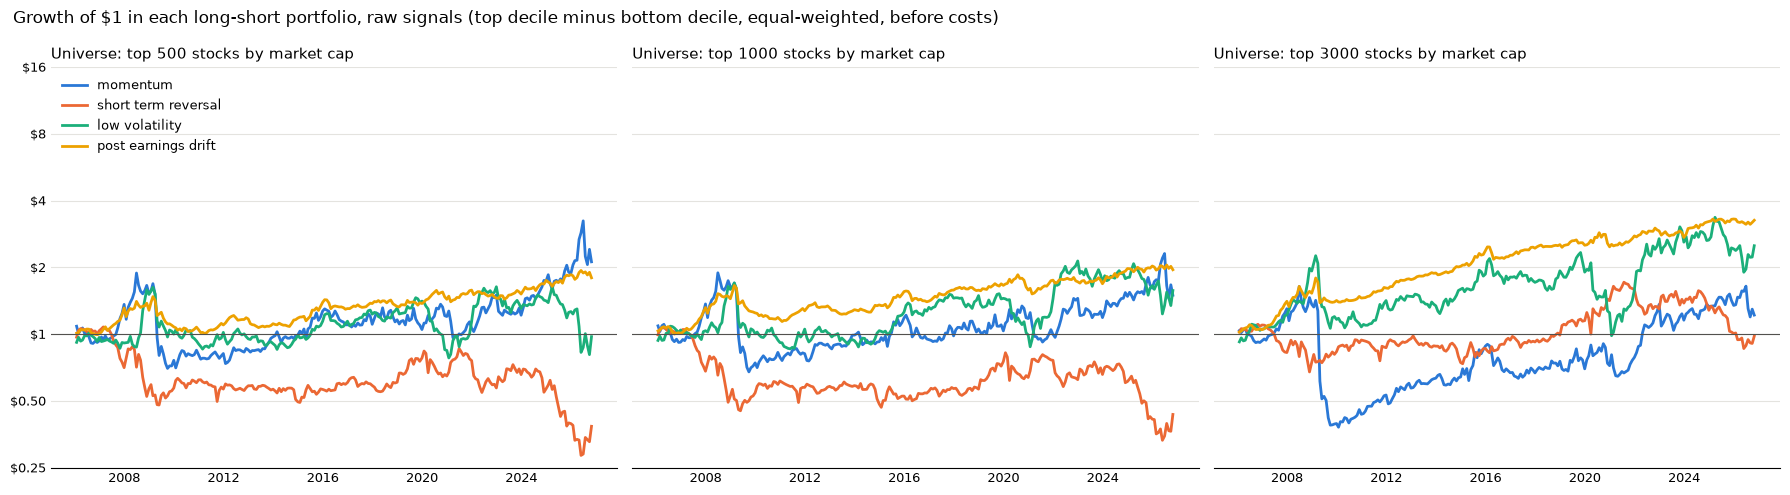

In [3]:
plot_cumulative_returns(long_short, "raw")

What to notice:

- **Momentum crash, spring 2009**: the stocks that fell most in 2008 rebounded hardest, and momentum was short them.
- **Low volatility, 2009**: the raw version is short the market, so it lost in the rebound.
- **Post-earnings drift** is the smoothest line.

## 4. Average return of each of the 10 groups

If a signal works, the bars should rise from group 1 (lowest score) to group 10 (highest score).
A long-short return that comes only from one extreme group is weaker evidence than a steady slope.

In [4]:
def group_means(portfolios):
    """Average monthly return (%) of each of the 10 groups, one row per (signal, universe)."""
    return pd.DataFrame({key: 100 * table.drop(columns="long_short").mean() for key, table in portfolios.items()}).T


decile_means = group_means(portfolios)
decile_means

,group,1,2,3,4,5,6,7,8,9,10
momentum,top 500,0.65,0.88,0.95,0.85,0.97,1.05,0.89,0.96,0.87,1.19
short_term_reversal,top 500,0.90,0.93,0.82,0.97,0.94,1.00,0.95,1.05,0.92,0.67
low_volatility,top 500,0.82,0.91,0.85,0.88,0.85,0.95,0.87,1.03,1.04,0.97
post_earnings_drift,top 500,0.73,0.78,1.02,0.88,0.95,1.04,1.05,0.95,0.96,1.00
momentum,top 1000,0.67,0.80,1.01,0.93,0.96,0.96,0.89,0.85,0.85,1.05
short_term_reversal,top 1000,0.81,0.83,0.87,0.93,0.92,1.00,1.03,0.99,0.84,0.62
low_volatility,top 1000,0.60,0.78,0.85,0.78,1.01,0.95,0.93,0.99,1.01,0.94
post_earnings_drift,top 1000,0.66,0.79,0.97,0.99,0.90,0.94,0.98,0.93,0.99,0.96
momentum,top 3000,0.60,0.83,0.89,0.91,0.92,0.95,0.91,0.90,0.90,0.94
short_term_reversal,top 3000,0.62,0.72,0.79,0.86,0.92,0.98,1.01,0.95,0.83,0.73


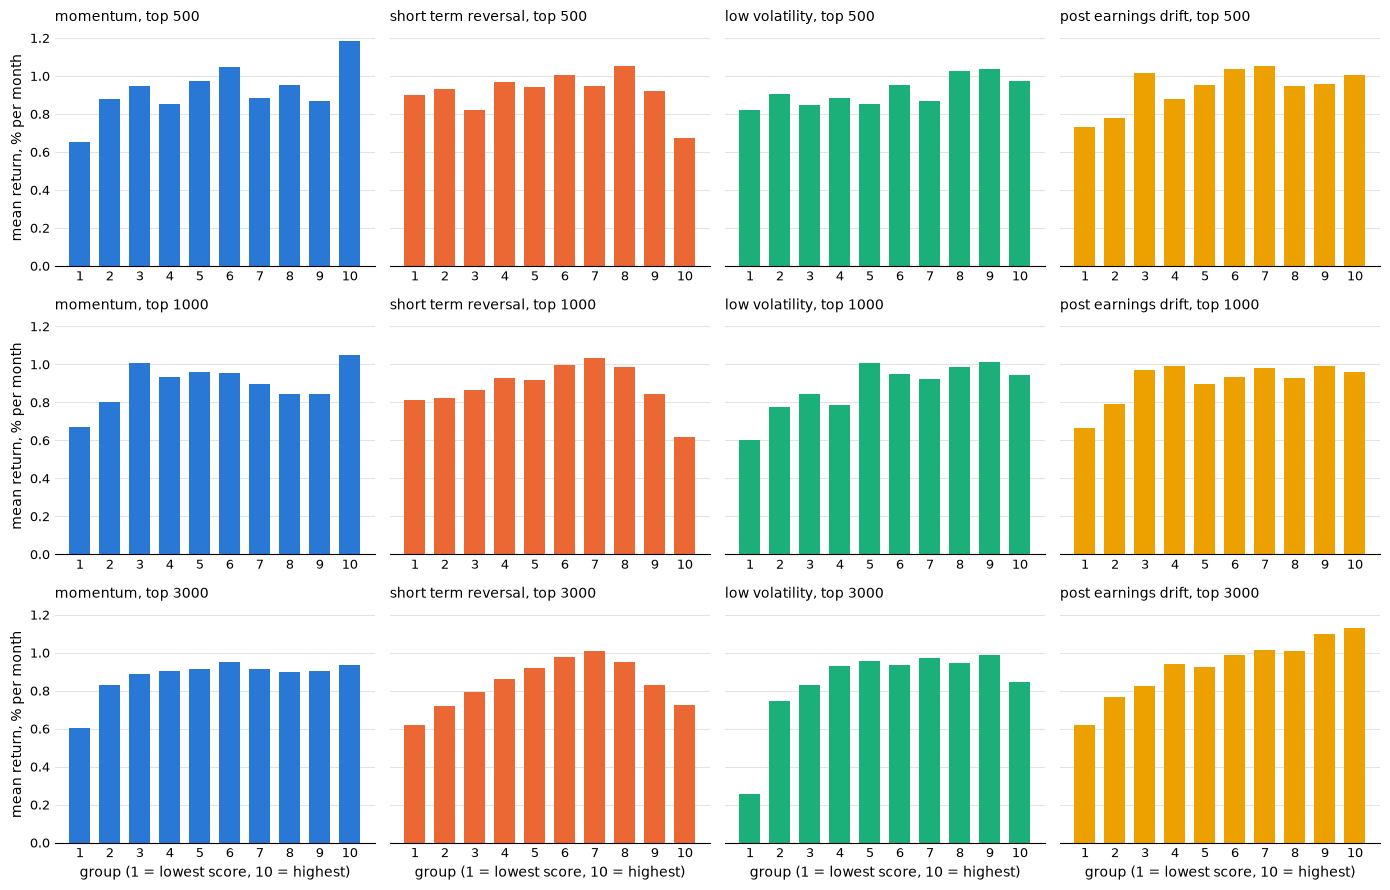

In [5]:
def plot_group_means(decile_means):
    """Bar chart of the 10 group returns: one row of panels per universe, one column per signal."""
    figure, axes = plt.subplots(len(UNIVERSE_SIZES), len(SIGNAL_COLORS), figsize=(14, 3 * len(UNIVERSE_SIZES)), sharey=True)
    for row, universe_name in enumerate(UNIVERSE_SIZES):
        for column, (signal_name, color) in enumerate(SIGNAL_COLORS.items()):
            axis = axes[row, column]
            means = decile_means.loc[(signal_name, universe_name)]
            axis.bar(means.index.astype(str), means, color=color, width=0.7)
            axis.set_title(f"{signal_name.replace('_', ' ')}, {universe_name}", loc="left", fontsize=10)
            axis.grid(axis="y", color="#e4e3df", linewidth=0.8)
            axis.set_axisbelow(True)
            axis.spines[["top", "right", "left"]].set_visible(False)
            axis.tick_params(length=0, labelsize=9)
        axes[row, 0].set_ylabel("mean return, % per month")
    for axis in axes[-1]:
        axis.set_xlabel("group (1 = lowest score, 10 = highest)")
    figure.tight_layout()
    plt.show()


plot_group_means(decile_means)

What to notice:

- **Momentum** rises steadily from group 1 to group 10: the cleanest slope of the four.
- **Short-term reversal** is a hump: both extreme groups earn less than the middle, so top minus bottom is about zero.
- **Low volatility**: groups 2 to 10 are almost flat. The whole effect is group 1 (the most volatile stocks)
  earning much less, so the profit comes from the short side.
- **Post-earnings drift** rises in the top 3000; in the top 500 it is again mostly group 1.

## 5. Two sub-periods

Mean long-short return (% per month) and t-stat in 2006-2015 and in 2016-2026 (the second one is the "last 10 years" of Part E).

In [6]:
periods = {"2006-2015": slice("2006", "2015"), "2016-2026": slice("2016", "2026")}
rows = {}
for period_name, years in periods.items():
    statistics = pd.DataFrame({key: summarize(returns.loc[years]) for key, returns in long_short.items()}).T
    rows[(period_name, "mean % per month")] = statistics["mean % per month"]
    rows[(period_name, "t-stat")] = statistics["t-stat"]
    rows[(period_name, "NW t-stat")] = statistics["NW t-stat"]
pd.DataFrame(rows).astype(float)

2006-2015                   \
                             mean % per month t-stat NW t-stat   
momentum            top 500              0.43   0.72      0.68   
short_term_reversal top 500             -0.35  -0.77     -0.82   
low_volatility      top 500              0.24   0.52      0.43   
post_earnings_drift top 500              0.32   1.15      1.19   
momentum            top 1000             0.36   0.62      0.54   
short_term_reversal top 1000            -0.42  -0.97     -1.00   
low_volatility      top 1000             0.33   0.70      0.60   
post_earnings_drift top 1000             0.41   1.61      1.46   
momentum            top 3000             0.22   0.34      0.29   
short_term_reversal top 3000            -0.02  -0.06     -0.07   
low_volatility      top 3000             0.68   1.35      1.14   
post_earnings_drift top 3000             0.77   2.85      3.20   

                                    2016-2026                   
                             mean % per month t-stat NW t-stat  
momentum            top 500              0.63   1.06      1.28  
short_term_reversal top 500             -0.12  -0.23     -0.23  
low_volatility      top 500              0.07   0.12      0.12  
post_earnings_drift top 500              0.22   1.10      1.30  
momentum            top 1000             0.40   0.70      0.86  
short_term_reversal top 1000             0.01   0.02      0.03  
low_volatility      top 1000             0.36   0.67      0.72  
post_earnings_drift top 1000             0.20   1.02      1.12  
momentum            top 3000             0.44   0.82      0.96  
short_term_reversal top 3000             0.23   0.50      0.57  
low_volatility      top 3000             0.51   0.78      0.80  
post_earnings_drift top 3000             0.27   1.34      1.52

## 6. Return by calendar year

Compounded long-short return of each year, in %. Shows which years made or lost the money.

In [7]:
yearly = 100 * ((1 + long_short.fillna(0)).groupby(long_short.index.year).prod() - 1)
yearly = yearly.where(long_short.groupby(long_short.index.year).count() > 0)  # blank before a signal starts
yearly.style.format("{:.0f}", na_rep="").background_gradient(cmap="RdBu", vmin=-60, vmax=60)

,momentum,short_term_reversal,low_volatility,post_earnings_drift,momentum,short_term_reversal,low_volatility,post_earnings_drift,momentum,short_term_reversal,low_volatility,post_earnings_drift
,top 500,top 500,top 500,top 500,top 1000,top 1000,top 1000,top 1000,top 3000,top 3000,top 3000,top 3000
date,,,,,,,,,,,,
2006,-7,3,-3,0,-8,3,4,1,-7,10,5,5
2007,46,-32,-6,31,49,-34,-1,31,40,-25,16,34
2008,12,-20,66,-2,20,-23,54,10,5,-10,58,9
2009,-50,1,-34,-16,-55,3,-37,-14,-71,12,-39,-7
2010,6,9,-10,-3,6,13,-9,-7,10,13,-7,3
2011,1,-9,13,5,4,-6,15,9,22,-8,31,11
2012,4,4,-7,6,7,1,-5,3,7,10,4,9
2013,15,-3,-5,-5,13,1,-7,-2,11,-7,-9,7


## 7. Correlation between the long-short portfolios

Monthly return correlation in the top 3000 universe. Low or negative correlation means two signals
diversify each other.

In [8]:
top_3000 = long_short.xs("top 3000", axis=1, level=1)
top_3000.corr()

,momentum,short_term_reversal,low_volatility,post_earnings_drift
momentum,1.00,-0.34,0.36,0.67
short_term_reversal,-0.34,1.00,-0.30,-0.28
low_volatility,0.36,-0.30,1.00,0.42
post_earnings_drift,0.67,-0.28,0.42,1.00


Momentum and post-earnings drift are strongly correlated (0.67): a stock with good earnings news has usually
also gone up over the past year, so the two signals pick many of the same stocks. Reversal is negatively
correlated with the other three.

---
# Part C. Sector- and beta-neutral signals

### Why

A raw long-short portfolio carries bets we did not ask for:

- **Market beta.** Low volatility buys calm stocks and shorts wild ones, so it is short the market
  (beta about -1). Momentum's beta changes with the recent market direction.
- **Sectors.** In 1999 the momentum winners and the high-volatility stocks were mostly technology.

These bets add a lot of volatility and little average return. Neutralizing keeps only the comparison of
a stock with similar stocks.

### Construction (`neutralize.py`)

**Beta.** For each stock at each month-end, the slope of its daily excess return on the market's daily
excess return over the latest 252 trading days (at least 120 needed):

$$\beta_i = \frac{\text{cov}(r_i - RF,\ MKT)}{\text{var}(MKT)}$$

**Neutral score.** At each month-end, separately inside each sector of the universe:

1. Rank the scores and scale the rank to between 0 and 1 (0 = lowest score of the sector, 1 = highest).
   Extreme scores no longer dominate.
2. Turn the rank into a z-score: subtract the sector's average rank and divide by the sector's
   standard deviation of ranks. Every sector now has mean 0 and standard deviation 1.
3. Regress the z-score on beta, with the sector's own intercept and slope (betas beyond the month's 1st
   or 99th percentile are first pulled in to that percentile):

$$z_i = a_{\text{sector}} + c_{\text{sector}} \, \beta_i + \varepsilon_i$$

4. The residual $\varepsilon_i$ is the new score. Inside every sector it averages zero and is
   uncorrelated with beta: a high value means "high score compared with stocks of the same sector and
   the same beta".

Then the same 10 groups (sorted across the whole universe) and the same top-minus-bottom portfolio.

**How much each sector gets.** Every stock has equal weight and every sector has the same spread of
scores, so each sector's share of a group is about its share of the stocks in the universe. In the
top 3000 that is on average 18% financials, 15% technology, 14% industrials, 13% healthcare, down to
3% utilities.

**This makes the score neutral, not exactly the portfolio.** Measured on the resulting top and bottom groups:

- **Sectors.** The largest difference in any one sector's weight between the top and the bottom group
  is on average 2% to 4% in the top 3000 and 6% to 7% in the top 500 (50 stocks per group, so one stock
  is 2%). For the raw momentum signal in the top 3000 it is 22%.
- **Beta.** The 10 groups hold equal dollar amounts, and nothing forces the top and bottom group to
  have the same beta. The `market beta` column below measures what is left: the slope of the monthly
  long-short return on the monthly market excess return.

## C.1 Raw and neutral side by side

In [9]:
all_summary = build_summary(all_long_short)
comparison = all_summary.unstack(0).swaplevel(axis=1)  # one row per (signal, universe)
columns = ["mean % per month", "t-stat", "NW t-stat", "annual Sharpe", "max drawdown %", "market beta"]
comparison = comparison.reindex(index=portfolios.keys())
pd.concat({version: comparison[version][columns].astype(float) for version in ["raw", "neutral"]}, axis=1)

raw                                 \
                             mean % per month t-stat NW t-stat annual Sharpe   
momentum            top 500              0.53   1.27      1.34          0.28   
short_term_reversal top 500             -0.23  -0.66     -0.69         -0.15   
low_volatility      top 500              0.15   0.42      0.38          0.09   
post_earnings_drift top 500              0.27   1.59      1.71          0.35   
momentum            top 1000             0.38   0.93      0.95          0.20   
short_term_reversal top 1000            -0.20  -0.59     -0.62         -0.13   
low_volatility      top 1000             0.34   0.96      0.94          0.21   
post_earnings_drift top 1000             0.30   1.89      1.85          0.41   
momentum            top 3000             0.33   0.79      0.76          0.17   
short_term_reversal top 3000             0.11   0.35      0.41          0.08   
low_volatility      top 3000             0.59   1.42      1.36          0.31   
post_earnings_drift top 3000             0.51   3.05      3.37          0.67   

                                                                 neutral  \
                             max drawdown % market beta mean % per month   
momentum            top 500          -62.84       -0.25             0.40   
short_term_reversal top 500          -73.65        0.31             0.05   
low_volatility      top 500          -52.00       -0.63             0.46   
post_earnings_drift top 500          -31.78       -0.13             0.40   
momentum            top 1000         -64.24       -0.28             0.34   
short_term_reversal top 1000         -68.87        0.38            -0.01   
low_volatility      top 1000         -49.54       -0.68             0.35   
post_earnings_drift top 1000         -31.21       -0.15             0.30   
momentum            top 3000         -76.80       -0.47             0.26   
short_term_reversal top 3000         -49.76        0.46             0.25   
low_volatility      top 3000         -57.82       -0.94             0.57   
post_earnings_drift top 3000         -22.71       -0.19             0.54   

                                                                            \
                             t-stat NW t-stat annual Sharpe max drawdown %   
momentum            top 500    1.87      1.80          0.41         -40.79   
short_term_reversal top 500    0.29      0.27          0.06         -40.85   
low_volatility      top 500    3.16      3.45          0.69         -21.52   
post_earnings_drift top 500    3.25      3.33          0.71         -18.78   
momentum            top 1000   1.54      1.51          0.34         -42.17   
short_term_reversal top 1000  -0.06     -0.05         -0.01         -40.99   
low_volatility      top 1000   2.52      2.46          0.55         -31.20   
post_earnings_drift top 1000   2.83      2.89          0.62         -12.51   
momentum            top 3000   1.08      0.97          0.24         -57.65   
short_term_reversal top 3000   1.32      1.27          0.29         -31.35   
low_volatility      top 3000   2.90      2.59          0.64         -43.53   
post_earnings_drift top 3000   5.37      5.42          1.18          -8.20   

                                          
                             market beta  
momentum            top 500        -0.16  
short_term_reversal top 500         0.15  
low_volatility      top 500        -0.04  
post_earnings_drift top 500        -0.09  
momentum            top 1000       -0.19  
short_term_reversal top 1000        0.20  
low_volatility      top 1000       -0.07  
post_earnings_drift top 1000       -0.09  
momentum            top 3000       -0.25  
short_term_reversal top 3000        0.25  
low_volatility      top 3000       -0.20  
post_earnings_drift top 3000       -0.07

What to notice:

- **Market beta** moves towards zero everywhere: low volatility from -0.63 to -0.04 (top 500) and
  from -0.94 to -0.20 (top 3000), momentum from -0.47 to -0.25 (top 3000). Not exactly zero, as expected.
- **Every drawdown is smaller.**
- **Short-term reversal** goes from 0.11% per month (t = 0.3) to 0.25% (t = 1.3) in the
  top 3000. When a whole sector falls it is usually news, and news does not reverse. A stock that falls
  **relative to its sector** is more often a liquidity event, and that does reverse. In the top 500 and top 1000
  there is nothing left (t = 0.3 and -0.1): large stocks are liquid, so there is less to be paid for.
- **Low volatility** gains the most: it loses most of its volatility (the raw version was mainly a
  short-the-market position) and keeps or raises its mean, from 0.15% to 0.46% in the top 500
  (t = 3.2) and 0.59% to 0.57% in the top 3000 (t = 2.9).
- **Momentum** loses part of its mean (0.53% to 0.40% in the top 500, 0.33% to 0.26% in the top
  3000, t = 1.9 and 1.1). Part of raw
  momentum is sector momentum: buying the sectors that went up (Moskowitz and Grinblatt 1999).
- **Post-earnings drift** keeps or raises its mean in every universe (t = 3.3, 2.8 and 5.4 in the
  top 500, 1000 and 3000) and has the smallest drawdown (-8% to -19%).

**The numbers depend on how exactly we neutralize.** Top 3000, mean % per month (t-stat) for three
versions of step 3, measured on the earlier 1999-2026 sample with the plain (not decayed)
post-earnings drift (not rerun on 2006-2026):

| Signal | sector z-scores only, no beta | one beta slope for all sectors | one beta slope per sector (used here) |
|---|---|---|---|
| momentum | 0.57 (1.67) | 0.57 (2.41) | 0.39 (1.69) |
| short-term reversal | 0.42 (1.68) | 0.53 (2.67) | 0.50 (2.54) |
| low volatility | 0.51 (1.46) | 0.36 (1.80) | 0.36 (1.80) |
| post-earnings drift | 0.33 (2.43) | 0.33 (3.09) | 0.29 (2.91) |

Reversal, low volatility and post-earnings drift barely change between the last two columns.
Momentum does: a t-stat that moves from 2.4 to 1.7 with a small change of method is not a robust result.

## C.2 Growth of $1, neutral signals

Same scale as the raw chart in section 3.

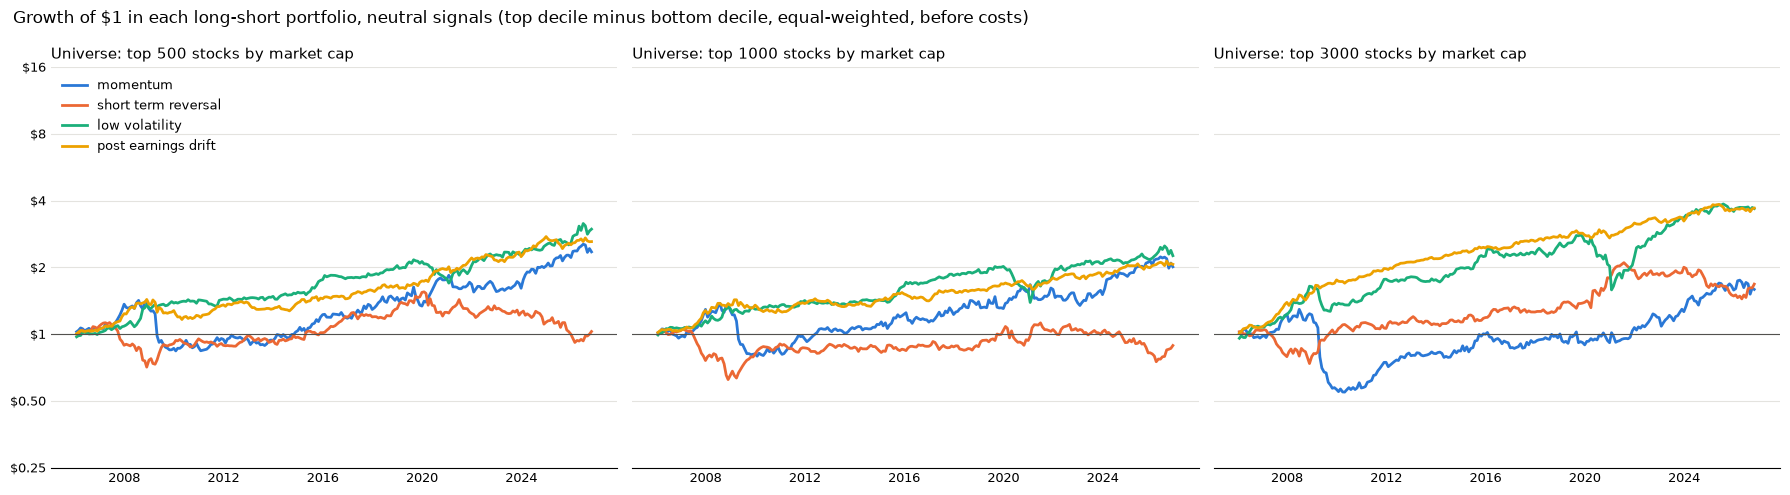

In [10]:
plot_cumulative_returns(all_long_short["neutral"], "neutral")

What to notice:

- **Reversal** earned most of its return before 2003 and in 2020-21 (high-volatility periods, when
  liquidity is expensive). Since 2021 it has lost money.
- **The 2009 momentum crash is still there**, and in the top 3000 it is almost as deep as before.
  Neutralizing against a one-year beta does not remove it, because the betas of the loser stocks
  changed quickly in that period.

## C.3 Average return of each of the 10 groups, neutral signals

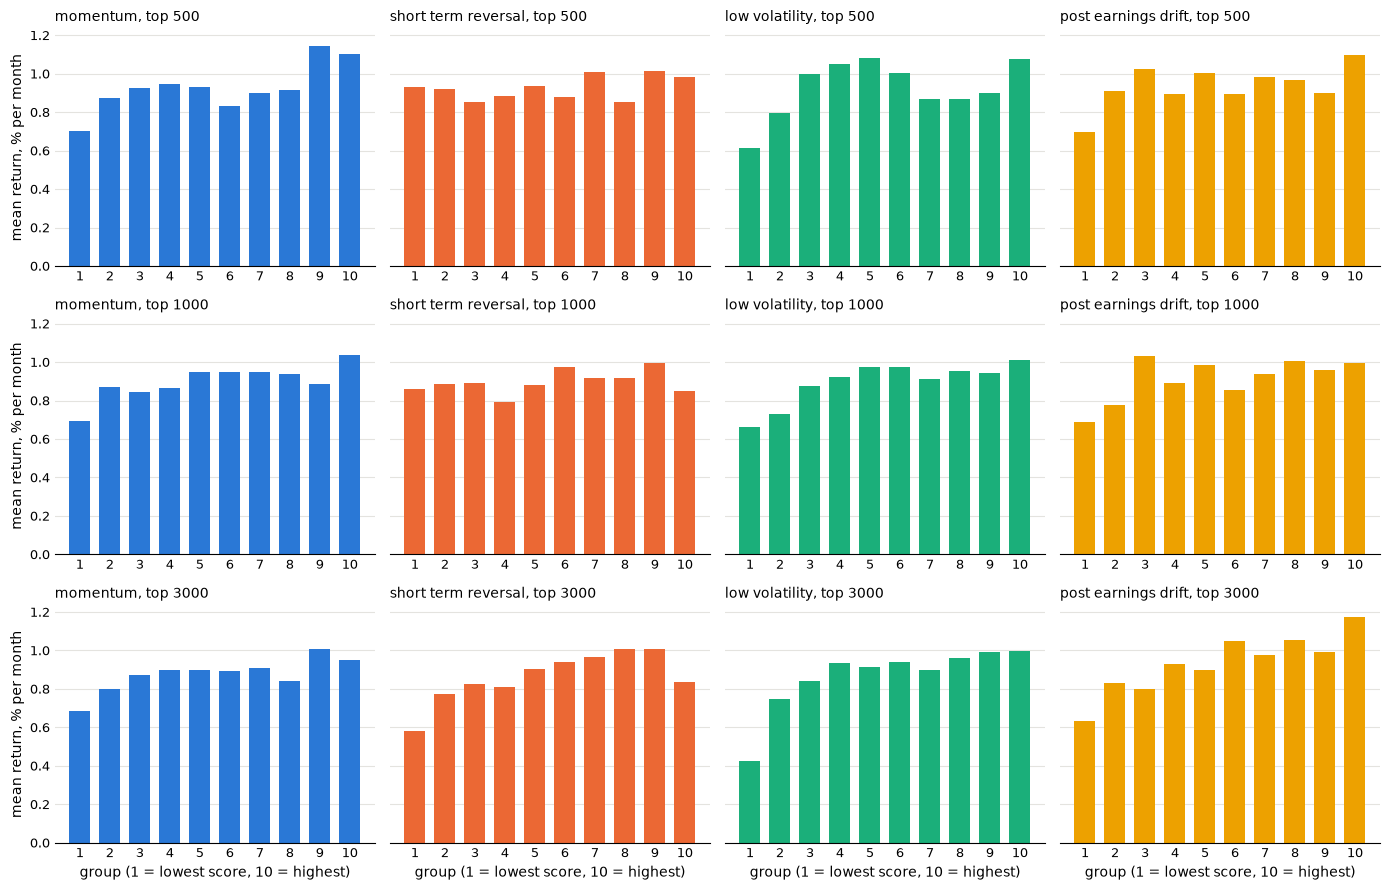

,group,1,2,3,4,5,6,7,8,9,10
momentum,top 500,0.70,0.87,0.92,0.95,0.93,0.83,0.90,0.91,1.14,1.10
short_term_reversal,top 500,0.93,0.92,0.85,0.88,0.94,0.88,1.01,0.86,1.01,0.98
low_volatility,top 500,0.61,0.80,1.00,1.05,1.08,1.00,0.87,0.87,0.90,1.08
post_earnings_drift,top 500,0.70,0.91,1.02,0.89,1.00,0.89,0.98,0.97,0.90,1.10
momentum,top 1000,0.69,0.87,0.84,0.87,0.95,0.95,0.95,0.94,0.89,1.04
short_term_reversal,top 1000,0.86,0.89,0.89,0.79,0.88,0.98,0.92,0.92,1.00,0.85
low_volatility,top 1000,0.66,0.73,0.87,0.92,0.98,0.98,0.91,0.95,0.94,1.01
post_earnings_drift,top 1000,0.69,0.78,1.03,0.89,0.99,0.85,0.94,1.00,0.96,0.99
momentum,top 3000,0.69,0.80,0.87,0.90,0.90,0.89,0.91,0.84,1.01,0.95
short_term_reversal,top 3000,0.58,0.77,0.82,0.81,0.90,0.94,0.96,1.01,1.01,0.84


In [11]:
neutral_portfolios = {key[1:]: table for key, table in all_portfolios.items() if key[0] == "neutral"}
neutral_decile_means = group_means(neutral_portfolios)
plot_group_means(neutral_decile_means)
neutral_decile_means

The spread between group 10 and group 1 is now more evenly split between the two ends, and the
reversal hump is gone: its group returns rise from 1 to 10.

## C.4 Correlation between the neutral long-short portfolios (top 3000)

In [12]:
all_long_short["neutral"].xs("top 3000", axis=1, level=1).corr()

,momentum,short_term_reversal,low_volatility,post_earnings_drift
momentum,1.00,-0.48,0.20,0.49
short_term_reversal,-0.48,1.00,-0.29,-0.35
low_volatility,0.20,-0.29,1.00,0.14
post_earnings_drift,0.49,-0.35,0.14,1.00


---
# Part D. The four signals combined

Four signals held together: momentum, short-term reversal, low volatility and post-earnings drift
(section A.4). Built in two steps (`combine_weights` in `portfolio.py`):

1. **Equal capital.** Give a quarter of the capital to each long-short portfolio and add up the
   holdings stock by stock. A stock that one signal buys and another shorts cancels. After this step
   the portfolio is long about \$0.76 and short about \$0.76 for every \$1 its parts were.
2. **Scale back.** Multiply the long side and the short side so that each is \$1 again. The combined
   portfolio is then \$1 long / \$1 short like every single signal, so its return, its volatility and
   its costs can be compared with theirs directly.

Before step 2 the return would be the plain average of the four long-short returns. Step 2 multiplies
it by about 1.3 (1 / 0.76) and the volatility by the same factor, so the Sharpe ratio hardly changes.
There is no parameter to choose. The combined portfolio exists only in months where all four signals
have a return, which is every month from 2006-01.

## D.1 Summary

In [13]:
from anomaly_replication.backtest import plot_combined_returns

combined_summary = build_summary(with_combined).xs(COMBINED, level=1)
combined_summary

,,first month,months,mean % per month,t-stat,NW t-stat,annual Sharpe,max drawdown %,market beta
raw,top 500,2006-01,250,0.25,1.22,1.24,0.27,-38.03,-0.22
neutral,top 500,2006-01,250,0.43,4.00,4.77,0.88,-12.42,-0.04
raw,top 1000,2006-01,250,0.29,1.36,1.33,0.30,-39.87,-0.23
neutral,top 1000,2006-01,250,0.32,3.27,3.49,0.72,-13.13,-0.05
raw,top 3000,2006-01,250,0.50,2.19,2.04,0.48,-46.06,-0.35
neutral,top 3000,2006-01,250,0.53,4.97,4.57,1.09,-15.81,-0.09


For comparison, the four single signals over the same months (neutral version, top 3000):

In [14]:
same_months = with_combined["neutral"].xs("top 3000", axis=1, level=1).dropna()
pd.DataFrame({name: summarize(returns) for name, returns in same_months.items()}).T

,first month,months,mean % per month,t-stat,NW t-stat,annual Sharpe,max drawdown %
momentum,2006-01,250,0.26,1.08,0.97,0.24,-57.65
short_term_reversal,2006-01,250,0.25,1.32,1.27,0.29,-31.35
low_volatility,2006-01,250,0.57,2.90,2.59,0.64,-43.53
post_earnings_drift,2006-01,250,0.54,5.37,5.42,1.18,-8.20
combined,2006-01,250,0.53,4.97,4.57,1.09,-15.81


What to notice:

- **The volatility is far below that of most parts.** In the neutral top 3000 the four parts have a
  monthly volatility of 1.6% to 3.8%; the combination has 1.7%, although it holds the same \$1 long
  and \$1 short.
- **The Sharpe ratio is 1.09, against 0.24 (momentum), 0.29 (reversal) and 0.64 (low volatility).**
  It is a little below post-earnings drift alone (1.18): that part is already very steady in
  the top 3000, and the other three add return but also their own risk.
- **The reason is the correlations** (section C.4). Reversal is negatively correlated with momentum
  and with post-earnings drift: when one loses, the other tends to gain. Momentum and post-earnings
  drift are positively correlated, so that pair adds little diversification.
- **Neutral beats raw by a wide margin** (t = 5.0 against 2.2 in the top 3000). The raw signals share
  the same market and sector bets, so their losses come together; the neutral ones do not.
- **The drawdown is -16%** (top 3000) and -12% (top 500), close to the smallest of the single signals.
- All of this is before costs. Part F subtracts them.

## D.2 Growth of $1

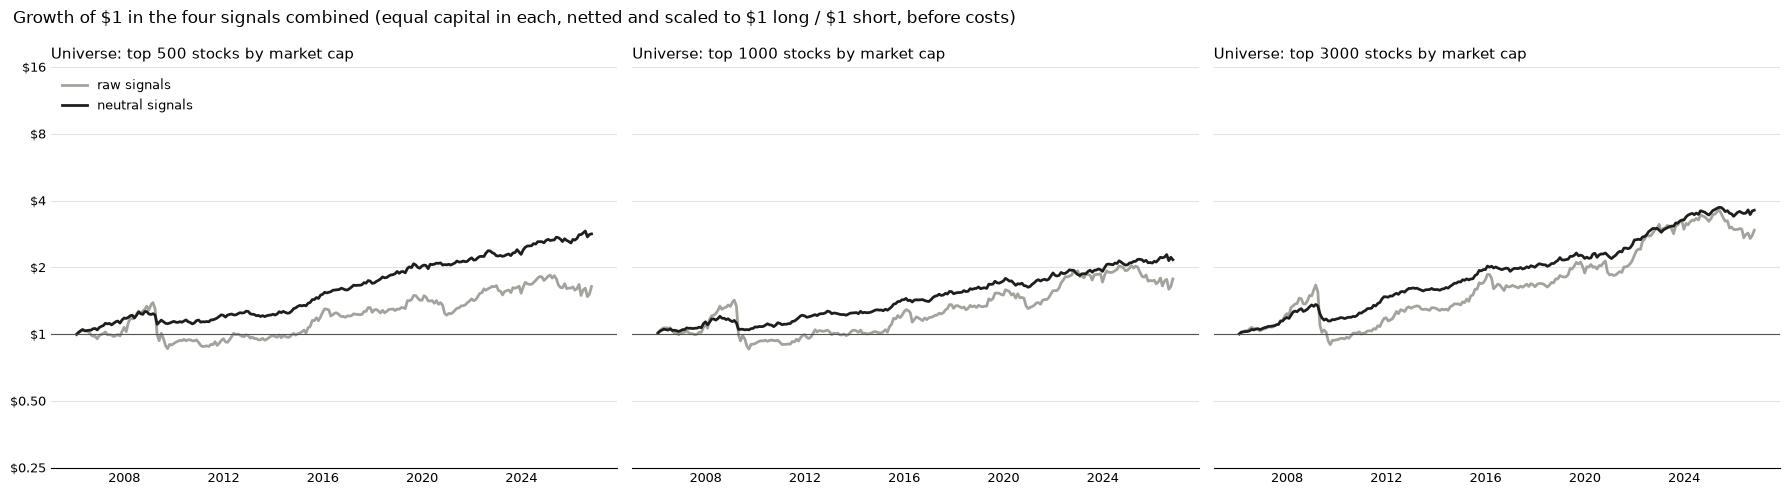

In [15]:
plot_combined_returns(with_combined)

---
# Part E. The last 10 years

The same portfolios, counting only the last 120 months (2016-11 to 2026-10). Nothing is rebuilt:
the scores and the holdings are the same, only the months that enter the statistics change.
All four papers were published well before 2016, so this period is entirely after publication.

## E.1 Summary, raw and neutral

In [16]:
from anomaly_replication.backtest import RECENT_MONTHS, RECENT_PERIOD

recent = with_combined.iloc[-RECENT_MONTHS:]
recent_summary = build_summary(recent)
recent_comparison = recent_summary.unstack(0).swaplevel(axis=1)  # one row per (signal, universe)
recent_comparison = recent_comparison.reindex(index=recent["neutral"].columns)
pd.concat({version: recent_comparison[version][columns].astype(float) for version in ["raw", "neutral"]}, axis=1)

raw                                 \
                             mean % per month t-stat NW t-stat annual Sharpe   
momentum            top 500              0.77   1.22      1.49          0.38   
short_term_reversal top 500             -0.18  -0.33     -0.33         -0.10   
low_volatility      top 500              0.11   0.20      0.19          0.06   
post_earnings_drift top 500              0.28   1.37      1.64          0.43   
combined            top 500              0.31   1.09      1.29          0.34   
momentum            top 1000             0.58   0.96      1.21          0.30   
short_term_reversal top 1000            -0.02  -0.03     -0.04         -0.01   
low_volatility      top 1000             0.36   0.63      0.68          0.20   
post_earnings_drift top 1000             0.29   1.47      1.67          0.46   
combined            top 1000             0.39   1.34      1.52          0.42   
momentum            top 3000             0.65   1.18      1.44          0.37   
short_term_reversal top 3000             0.17   0.35      0.40          0.11   
low_volatility      top 3000             0.54   0.80      0.82          0.25   
post_earnings_drift top 3000             0.34   1.70      1.99          0.54   
combined            top 3000             0.54   1.75      1.81          0.55   

                                                                 neutral  \
                             max drawdown % market beta mean % per month   
momentum            top 500          -36.49       -0.11             0.62   
short_term_reversal top 500          -67.03        0.25            -0.06   
low_volatility      top 500          -50.63       -0.54             0.46   
post_earnings_drift top 500          -11.16       -0.00             0.49   
combined            top 500          -20.18       -0.14             0.49   
momentum            top 1000         -37.26       -0.20             0.52   
short_term_reversal top 1000         -59.69        0.36             0.05   
low_volatility      top 1000         -42.34       -0.65             0.27   
post_earnings_drift top 1000         -18.06       -0.06             0.32   
combined            top 1000         -21.74       -0.18             0.37   
momentum            top 3000         -28.72       -0.49             0.52   
short_term_reversal top 3000         -49.76        0.53             0.26   
low_volatility      top 3000         -57.82       -0.98             0.46   
post_earnings_drift top 3000         -13.62       -0.09             0.36   
combined            top 3000         -25.69       -0.33             0.52   

                                                                            \
                             t-stat NW t-stat annual Sharpe max drawdown %   
momentum            top 500    1.93      2.21          0.61         -17.92   
short_term_reversal top 500   -0.22     -0.23         -0.07         -40.85   
low_volatility      top 500    1.84      2.18          0.58         -21.52   
post_earnings_drift top 500    2.76      3.05          0.87         -11.71   
combined            top 500    3.00      4.07          0.95          -5.96   
momentum            top 1000   1.57      1.94          0.50         -19.44   
short_term_reversal top 1000   0.18      0.17          0.06         -33.18   
low_volatility      top 1000   1.12      1.08          0.35         -31.20   
post_earnings_drift top 1000   2.15      2.49          0.68          -8.59   
combined            top 1000   2.35      2.86          0.74          -8.79   
momentum            top 3000   1.56      2.14          0.49         -13.54   
short_term_reversal top 3000   0.86      0.86          0.27         -31.35   
low_volatility      top 3000   1.38      1.32          0.44         -43.53   
post_earnings_drift top 3000   2.37      2.56          0.75          -8.20   
combined            top 3000   3.12      3.34          0.99          -8.88   

                                          
                  

What to notice:

- **The combined neutral portfolio holds up**: Sharpe 0.95 (top 500), 0.74 (top 1000), 0.99 (top 3000),
  against 0.88, 0.72 and 1.09 over the full sample, and a drawdown of only -6% to -9%.
- **Short-term reversal is gone**: about zero in all three universes, negative in the top 500.
  It was already weak over the full sample (neutral Sharpe 0.29 at best, in the top 3000).
- **Momentum and low volatility are no worse than before** (neutral means of 0.5% to 0.6% and
  0.3% to 0.5% per month), but with 120 months their t-stats stay below 2.
- **Post-earnings drift is the steadiest**: the neutral version has a Sharpe of 0.7 to 0.9 in every
  universe.
- **Neutral still beats raw**: the raw combined portfolio has a Sharpe of 0.34 to 0.55.
- **Ten years is a short sample.** The standard error of an annual Sharpe ratio is about
  $1/\sqrt{10} = 0.32$, so a true Sharpe of 0.5 gives a t-stat of only 1.6. Single signals cannot
  be told apart from each other, or from zero, with much confidence here.

## E.2 Growth of $1, neutral signals

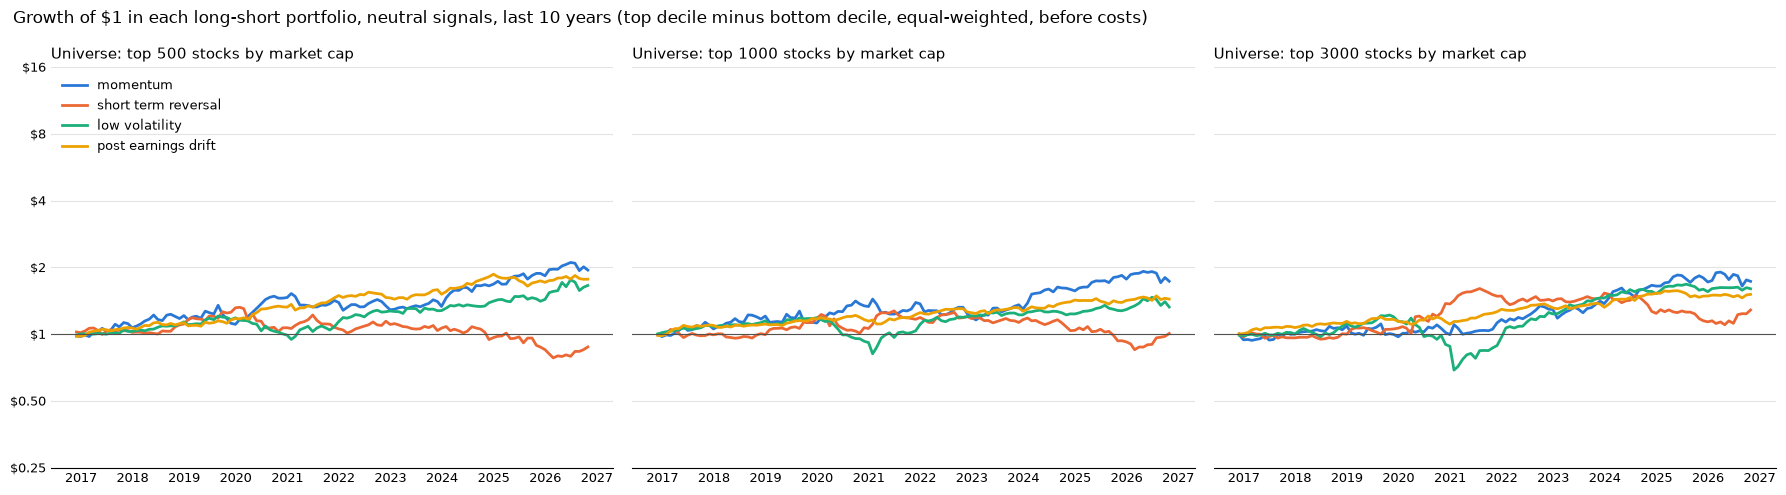

In [17]:
plot_cumulative_returns(recent["neutral"], "neutral", period=RECENT_PERIOD)

## E.3 Growth of $1, the four signals combined

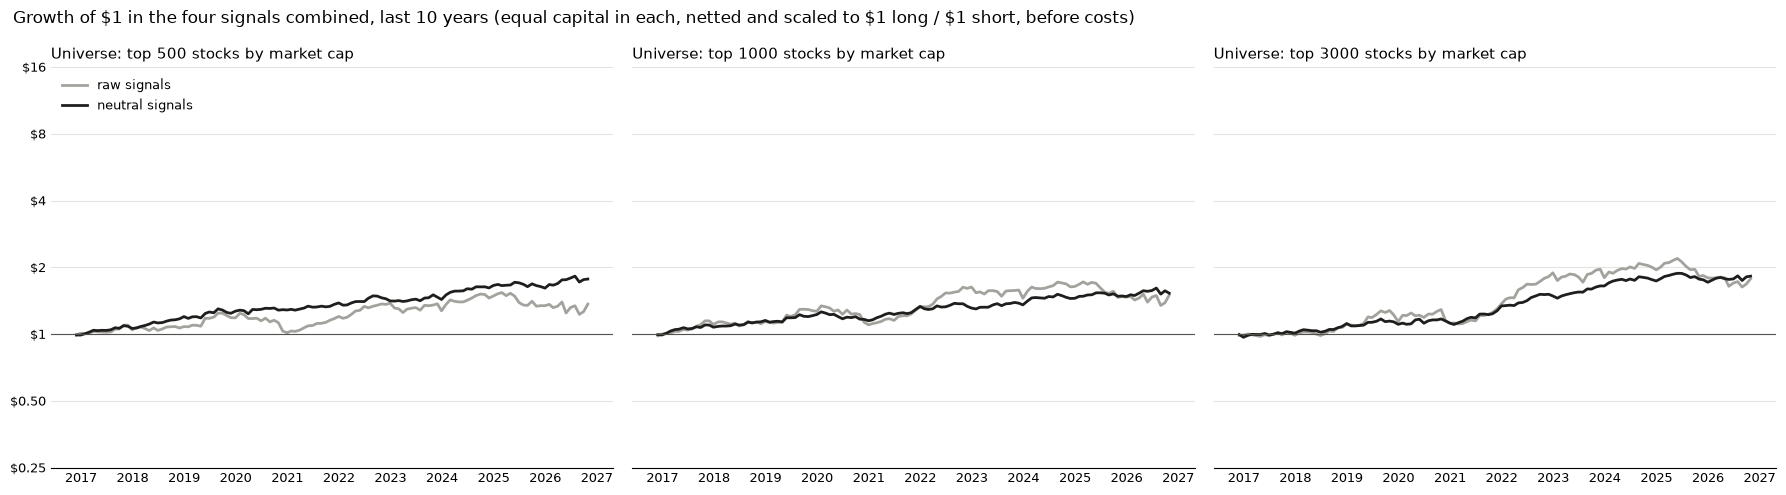

In [18]:
plot_combined_returns(recent, period=RECENT_PERIOD)

---
# Part F. After transaction costs

Everything above is before costs. This part subtracts a simple, standard estimate.

### Method (`portfolio.py`: `long_short_weights`, `dollars_traded`, `dollars_short`, `summarize_costs`)

**1. Holdings.** A long-short portfolio holds +\$1 of the top group and -\$1 of the bottom group,
equal weight per stock. The combined portfolio holds the average of its four portfolios stock by stock,
scaled back to +\$1 and -\$1 (Part D).

**2. Dollars traded.** During the month a position of $w$ dollars grows to $w(1+r)$. At the month-end
we trade from these drifted positions to the new weights, and buys and sells both count:

$$\text{traded}_t = \sum_i \left| w_{i,t} - w_{i,t-1}\,(1 + r_{i,t}) \right|$$

Replacing every stock on both sides gives about 4 (sell \$1 and buy \$1 long, cover \$1 and short \$1
short). **Turnover** = traded / 4: the share of each side replaced per month.

**3. Trading cost.** Every dollar traded costs a fixed number of basis points $c$ (1 bp = 0.01%).
$c$ stands for half the bid-ask spread (we buy at the ask and sell at the bid, the fair price is in
between) plus the price impact of our own order. We use 10 bp in the top 500, 15 bp in the top 1000
and 20 bp in the top 3000. The levels follow Frazzini, Israel and Moskowitz (2018, "Trading Costs"),
who measured about 9 bp for large caps and 19 bp for small caps on the real trades of a large manager.

**4. Borrowing fee.** To short a stock we borrow it from an owner, who charges a fee $f$ per year on
the dollars held short. The cash from the short sale earns about the risk-free rate, so the long-short
return already is an excess return (section 2); the fee is what the short side costs on top of that.
We use 0.25% per year in the top 500, 0.5% in the top 1000 and 1% in the top 3000. D'Avolio (2002,
"The Market for Borrowing Stock") found that 91% of stocks cost under 1% per year to borrow (0.17% on
average) and the other 9%, mostly small stocks, 4.3% on average. Every portfolio here is short \$1.

$$\text{net return}_t = \text{gross return}_t - \text{traded}_t \times c - \text{short}_t \times \frac{f}{12}$$

**Break-even cost** needs no assumption about $c$: it is the $c$ at which the average net return is
zero after paying the borrowing fee: (average gross return - average borrow cost) / average traded.
A strategy survives only if it can trade for less.

## F.1 Neutral version, full sample

In [19]:
from anomaly_replication.backtest import BORROW_FEE_PCT, COST_BPS, build_cost_summary, net_returns, plot_net_returns

cost_summary = build_cost_summary(with_combined, all_traded, all_shorted)
cost_columns = ["turnover % per month", "gross mean % per month", "trading cost % per month", "borrow cost % per month",
                "net mean % per month", "net t-stat", "net NW t-stat", "net annual Sharpe", "break-even cost bps"]
cost_summary.loc["neutral", cost_columns].astype(float)

,,turnover % per month,gross mean % per month,trading cost % per month,borrow cost % per month,net mean % per month,net t-stat,net NW t-stat,net annual Sharpe,break-even cost bps
momentum,top 500,37.99,0.40,0.15,0.02,0.23,1.06,1.02,0.23,25.01
short_term_reversal,top 500,89.62,0.05,0.36,0.02,-0.33,-1.82,-1.72,-0.40,0.86
low_volatility,top 500,76.46,0.46,0.31,0.02,0.14,0.93,1.02,0.20,14.46
post_earnings_drift,top 500,58.44,0.40,0.23,0.02,0.15,1.21,1.23,0.27,16.40
combined,top 500,63.36,0.43,0.25,0.02,0.16,1.46,1.74,0.32,16.19
momentum,top 1000,36.62,0.34,0.22,0.04,0.08,0.36,0.35,0.08,20.47
short_term_reversal,top 1000,89.08,-0.01,0.53,0.04,-0.59,-3.38,-2.98,-0.74,-1.44
low_volatility,top 1000,74.56,0.35,0.45,0.04,-0.14,-1.00,-0.97,-0.22,10.34
post_earnings_drift,top 1000,59.41,0.30,0.36,0.04,-0.09,-0.89,-0.89,-0.19,11.05
combined,top 1000,63.12,0.32,0.38,0.04,-0.10,-1.01,-1.08,-0.22,11.07


What to notice:

- **Costs take almost everything.** The combined portfolio keeps 0.16% per month in the top 500
  (Sharpe 0.32, after 0.88 before costs) and is slightly negative in the top 1000 and the top 3000.
- **Turnover decides.** Reversal replaces 89% of each side every month: by construction, last month's
  losers are a new set of stocks every month. Low volatility replaces 69% to 76%, because one month of
  daily returns is a noisy measure. Reversal is negative after costs in every universe, low volatility
  in the top 1000 and top 3000. Momentum (35% to 38%) uses eleven months of returns, changes slowly,
  and keeps the most in the top 500.
- **Trading costs are much larger than borrowing fees.** For the combined portfolio: 0.25% to 0.49%
  per month to trade, 0.02% to 0.08% to borrow. The fee is felt most in the top 3000.
- **Post-earnings drift trades more than momentum** (58% to 62%): the decay favours the newest
  announcements, and those change every month. After costs it keeps 0.15% per month in the top 500
  and is slightly negative in the other two universes.
- **Combining saves trades.** Netting the four parts removes about a quarter of their positions and of
  their trades. After scaling back to \$1 long / \$1 short, the combined portfolio replaces 62% to 63%
  of each side per month, about the average of its parts (64% to 66%).
- **The break-even costs are -1 to 25 bp.** For the combined portfolio: 16 bp (top 500), 11 bp
  (top 1000), 18 bp (top 3000). The top 3000 has the largest gross return but also the highest costs.

## F.2 The last 10 years

In [20]:
recent_cost_summary = build_cost_summary(
    recent, all_traded.iloc[-RECENT_MONTHS:], all_shorted.iloc[-RECENT_MONTHS:]
)
recent_cost_summary.loc["neutral", cost_columns].astype(float)

,,turnover % per month,gross mean % per month,trading cost % per month,borrow cost % per month,net mean % per month,net t-stat,net NW t-stat,net annual Sharpe,break-even cost bps
momentum,top 500,37.67,0.62,0.15,0.02,0.44,1.39,1.60,0.44,39.47
short_term_reversal,top 500,89.61,-0.06,0.36,0.02,-0.44,-1.55,-1.61,-0.49,-2.31
low_volatility,top 500,77.90,0.46,0.31,0.02,0.13,0.50,0.60,0.16,14.04
post_earnings_drift,top 500,59.29,0.49,0.24,0.02,0.24,1.33,1.47,0.42,19.99
combined,top 500,63.50,0.49,0.25,0.02,0.22,1.33,1.80,0.42,18.60
momentum,top 1000,36.75,0.52,0.22,0.04,0.26,0.78,0.97,0.25,32.87
short_term_reversal,top 1000,89.43,0.05,0.54,0.04,-0.53,-1.97,-1.91,-0.62,0.18
low_volatility,top 1000,75.70,0.27,0.45,0.04,-0.23,-0.94,-0.91,-0.30,7.51
post_earnings_drift,top 1000,60.58,0.32,0.36,0.04,-0.09,-0.61,-0.70,-0.19,11.32
combined,top 1000,63.50,0.37,0.38,0.04,-0.05,-0.34,-0.42,-0.11,12.88


In the last 10 years the combined portfolio keeps 0.22% per month in the top 500 (Sharpe 0.42) and
is about zero in the other two universes. Momentum has the highest break-even cost (31 to 39 bp);
reversal has none, its gross return is about zero.

## F.3 Growth of $1 in the neutral combined portfolio, before and after costs

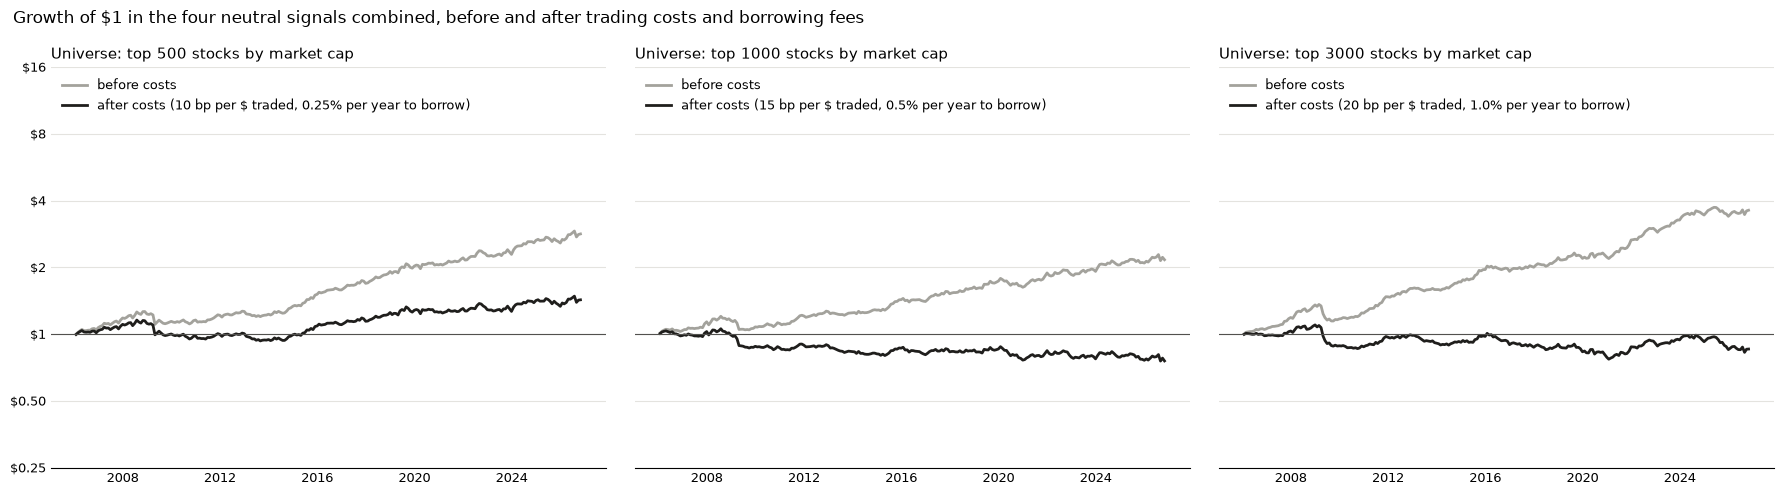

In [21]:
plot_net_returns(with_combined, net_returns(with_combined, all_traded, all_shorted))

### What this estimate leaves out

- **The trading cost is the same in every year.** Around 2000 spreads were several times wider (prices were
  quoted in fractions until 2001); today a large cap trades for a few bp. The estimate is too kind to
  the early years and probably too harsh on the recent years of the top 500.
- **The cost is the same for every stock of a universe**, and does not grow with the size of the
  order. In reality price impact grows with the order size relative to the stock's daily volume, which
  is what limits how much money a strategy can run.
- **The borrowing fee is the same for every stock and every year.** Real fees are highest for exactly
  the kind of stock these signals short (small, volatile, recent losers), and such stocks sometimes
  cannot be borrowed at all.
- **Nothing here tries to save costs.** The usual tools: trade less often; keep a stock until it
  leaves the top 20% instead of the top 10% (a "buy/hold spread", Novy-Marx and Velikov 2016); give
  less capital to the high-turnover signals; skip trades whose expected gain is below their cost.


---
# Part G. Capacity: how the result depends on the size of the fund

Part F charges the same cost for every dollar traded. The levels came from a paper on AQR's trades,
so they describe a very large manager. Most of that cost is **price impact**: a large order pushes
the price while it is being filled. A small order does not, and only pays the spread. So the cost,
and with it the net return, depends on how much money the strategy runs.

### Method (`capacity.py`, `liquidity.py`)

Every order of every month is priced separately:

$$\text{cost of an order, in bp} = \underbrace{\text{half spread}}_{\text{the same for any size}} + \underbrace{11.21 \times \sqrt{x}}_{\text{price impact}}, \qquad x = 100 \times \frac{\text{dollars in the order}}{\text{daily dollar volume of the stock}}$$

- **Price impact** follows the square-root law: an order four times larger costs twice as much per
  dollar. The coefficient 11.21 is the estimate of Frazzini, Israel and Moskowitz (2018, Table VII,
  U.S. sample) on \$1.7 trillion of real AQR trades from 1998 to 2016. Their average order was 0.9%
  of daily volume (the largest 13.1%), took 1.7 days, and cost 8.9 bp in large caps and 19 bp in
  small caps.
- **Half spread** is an assumption by the stock's market-cap rank at the month-end of the trade
  (`HALF_SPREAD_BPS`), the same in every universe: 1 bp for ranks 1 to 500, 3 bp for 501 to 1000,
  9 bp above 1000 or for a stock no longer in the top 3000 (one we are selling). In the table below,
  `spread bp per $ traded` is the result: the average half spread over all the dollars the
  portfolio trades (top 1000: 47% at 1 bp, 51% at 3 bp, 2% at 9 bp, so 2.2 bp). We tried to estimate each stock's spread from daily high, low and close
  prices (Abdi and Ranaldo 2017). For liquid stocks the estimate is mostly noise (zero in 4 months
  out of 10, and 20 bp on average for large caps in 2024, where the true value is 1 to 2 bp), so we
  do not use it.
- **Dollars in the order** = fund size × the change in the stock's weight (Part F, step 2).
  **Fund size** = dollars long = dollars short, in today's dollars. It is scaled back in time with
  the total dollar volume of the market, so the fund is the same share of market trading every year.
- **Daily dollar volume** is the 3-month average of close × volume. The vendor's volume is impossible
  for 0.6% of stock-months (for example \$70 per day for a top-500 stock); those are replaced by
  market cap × the month's median turnover.

## G.1 Net result at each fund size

In [22]:
capacity = pd.read_csv("../results/capacity.csv", index_col=[0, 1])  # written by capacity.py (takes about a minute)
capacity_columns = ["spread bp per $ traded", "impact bp per $ traded", "cost bp per $ traded", "net mean % per month",
                    "net annual Sharpe", "net annual Sharpe, last 10 years", "average order % of daily volume"]
capacity[capacity_columns].rename(index=lambda size: f"${size / 1e6:,.0f}M", level=1)

spread bp per $ traded  impact bp per $ traded  \
universe fund size $                                                   
top 500  $1M                            1.05                    0.51   
         $3M                            1.05                    0.88   
         $10M                           1.05                    1.61   
         $30M                           1.05                    2.79   
         $100M                          1.05                    5.10   
         $300M                          1.05                    8.83   
         $1,000M                        1.05                   16.12   
         $3,000M                        1.05                   27.91   
top 1000 $1M                            2.18                    0.55   
         $3M                            2.18                    0.96   
         $10M                           2.18                    1.75   
         $30M                           2.18                    3.03   
         $100M                          2.18                    5.53   
         $300M                          2.18                    9.57   
         $1,000M                        2.18                   17.48   
         $3,000M                        2.18                   30.27   
top 3000 $1M                            6.90                    1.11   
         $3M                            6.90                    1.93   
         $10M                           6.90                    3.52   
         $30M                           6.90                    6.09   
         $100M                          6.90                   11.12   
         $300M                          6.90                   19.26   
         $1,000M                        6.90                   35.17   
         $3,000M                        6.90                   60.92   

                      cost bp per $ traded  net mean % per month  \
universe fund size $                                               
top 500  $1M                          1.56                  0.37   
         $3M                          1.93                  0.36   
         $10M                         2.66                  0.34   
         $30M                         3.84                  0.31   
         $100M                        6.14                  0.25   
         $300M                        9.88                  0.16   
         $1,000M                     17.16                 -0.02   
         $3,000M                     28.96                 -0.32   
top 1000 $1M                          2.73                  0.21   
         $3M                          3.14                  0.20   
         $10M                         3.93                  0.18   
         $30M                         5.21                  0.15   
         $100M                        7.71                  0.08   
         $300M                       11.75                 -0.02   
         $1,000M                     19.66                 -0.22   
         $3,000M                     32.45                 -0.54   
top 3000 $1M                          8.01                  0.25   
         $3M                          8.83                  0.23   
         $10M                        10.42                  0.19   
         $30M                        12.99                  0.13   
         $100M                       18.02                  0.00   
         $300M                       26.17                 -0.20   
         $1,000M                     42.07                 -0.59   
         $3,000M                     67.82                 -1.23   

                      net annual Sharpe  net annual Sharpe, last 10 years  \
universe fund size $                                                        
top 500  $1M                       0.75                              0.83   
         $3M                       0.74                              0.81   
         $10M                      0.70                              0.7

## G.2 Net Sharpe ratio and cost against fund size

The dot on each line is the fund size at which our average order is 0.9% of daily volume, as large as
AQR's average order.

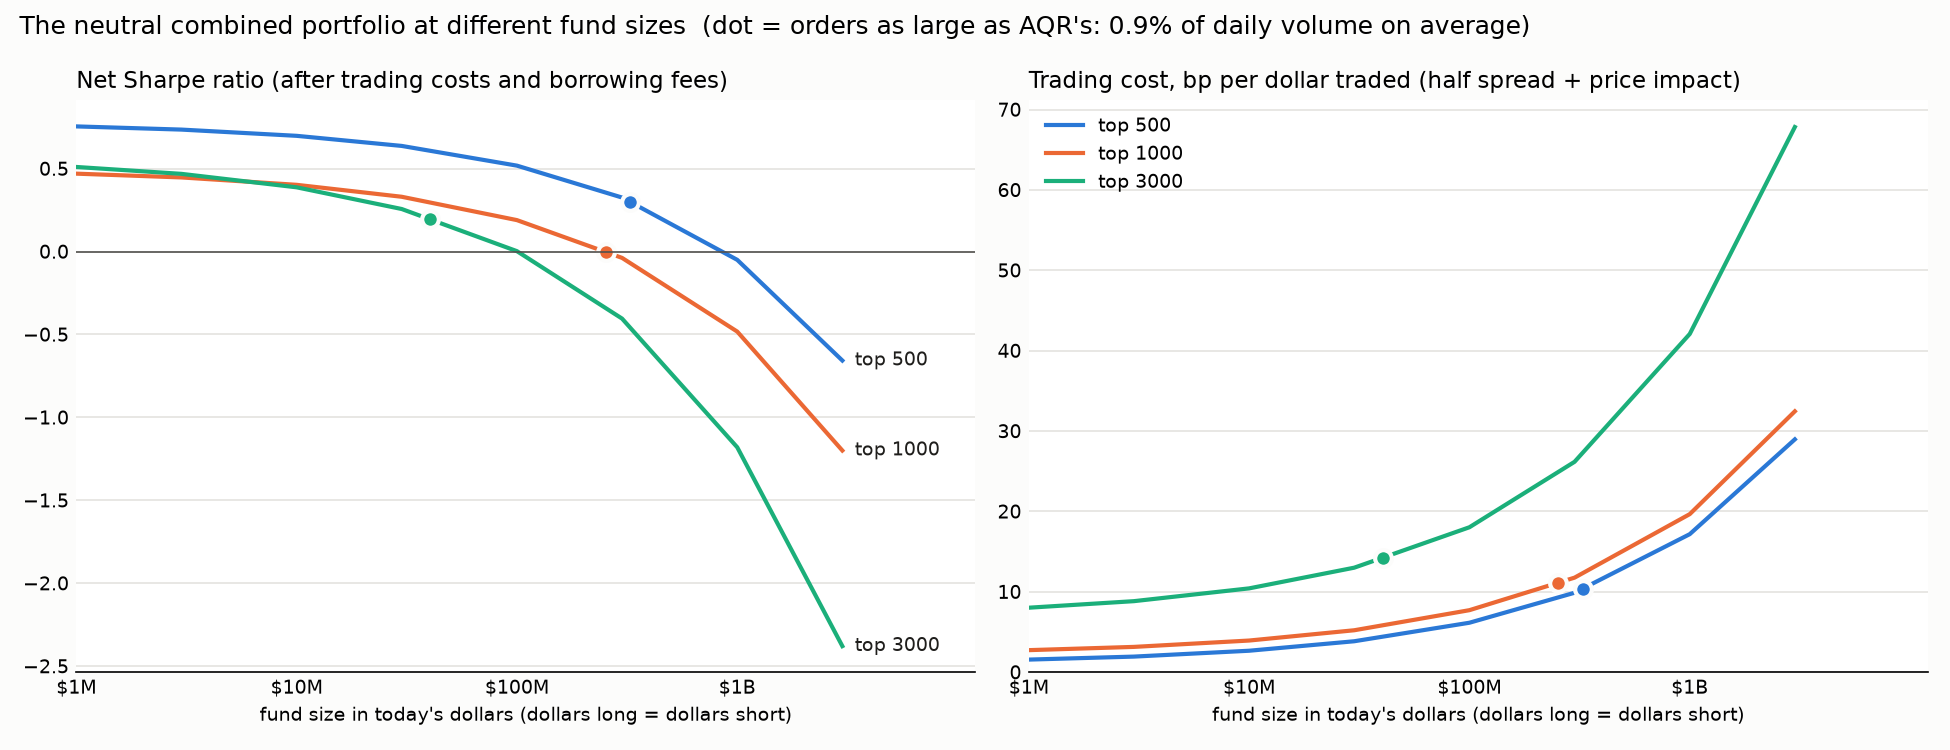

In [23]:
from IPython.display import Image

Image("../results/capacity.png")

What to notice:

- **A small fund keeps most of the return.** At \$1M to \$10M the top 500 portfolio has a net Sharpe of
  0.70 to 0.75 (0.88 before costs), and 0.78 to 0.83 in the last 10 years. Its orders are a few
  thousandths of a percent of daily volume: it pays the spread and almost no impact.
- **AQR-like orders.** Our average order reaches 0.9% of daily volume at a fund size of about \$330M
  in the top 500, \$250M in the top 1000 and \$40M in the top 3000. At those sizes the model's cost
  is 10 to 14 bp per dollar traded: in line with the 8.9 bp and 19 bp the paper measured, and with
  the flat 10 to 20 bp of Part F. So Part F is the result for a fund of that size.
- **Break-even fund size** (net return = 0): about \$850M in the top 500, \$250M in the top 1000,
  \$100M in the top 3000.
- **The top 3000 has the highest gross return and the lowest capacity.** Its small stocks have wide
  spreads (7 bp on average before any impact) and little volume.
- **Why so much smaller than the paper's numbers?** Frazzini, Israel and Moskowitz (2012) put the
  break-even size of the standard long-short momentum factor at \$52B and of short-term reversal at
  \$9.5B. Our portfolio holds few stocks with equal weights (at most 200 per side in the top 500, with
  as many dollars in the 500th stock as in the 1st), replaces 63% of them every month, and gives a
  quarter of its capital to reversal. Their factors hold many more stocks, weight them by market cap,
  and are traded patiently.

### Limits

- Every order is priced as one order. AQR's orders took 1.7 days on average; splitting an order
  over more days lowers its impact.
- The impact coefficient comes from a patient trader who uses limit orders. A trader who must be
  done at the open pays more.
- Above 13.1% of daily volume the square-root law is outside the paper's data: 2% of the dollars
  traded at \$1B in the top 500, 28% at \$1B in the top 3000.
- The half spread is the same in every year. Around 2000 it was several times wider.


---
# What is not in these numbers

- **Parts A to E are before transaction costs**; Part F subtracts a simple estimate and lists its limits.
- **Delisting returns.** A stock with no price in the holding month is dropped (about 0.4% of stock-months).
- **Point-in-time sectors.** The sector is the one the vendor assigns today. A company that changed
  business is placed in its current sector for the whole history.
- **Independent check.** Momentum and reversal (raw) were compared with the Ken French portfolios
  (long-short correlation 0.81 to 0.83). Low volatility, post-earnings drift and all neutral versions
  have not been checked against an outside source.
- **We chose the neutral version after seeing the raw results.** Each extra version tested makes a
  t-stat of 2 a little less impressive.